# LM31 Lab — Risk Parity, HRP and Volatility Targeting

Companion notebook to **From Calculus to Kelly, LM31**. It rebuilds the module's exhibits and computational examples from E5's two frames, the through case's per-trade targets and wealth paths, and the TWSE sector closes of U28. It re-implements R6, R7 and R8 at every signal and checks them against the through case, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: E5's estimation and wealth frames, $T$, $A$, $A_{\mathrm w}$, the 92 signals and the first window |
| 2 | Risk contributions and shares: Example 1, Example 2, Exhibit 2, equal correlations |
| 3 | ERC and budgets: Newton, CCD, the fixed point and cvxpy (Example 3, Example 4, problem 11), the widget's start |
| 4 | HRP by hand (Example 5, Example 6), the author's code and its `ClusterWarning`, linking on $d$; R7 at every signal (problem 12) |
| 5 | U28: Exhibit 3, Exhibit 4, the in-sample volatilities and Exhibit 6 |
| 6 | R6 out of sample (Exhibit 5, Example 7); R8 at every signal, Example 8, the EWMA matrix identity, Exhibit 7 |
| 7 | Holding months: Exhibit 8, QLIKE, Example 10, Example 9 and the case (Exhibit 1) |
| 8 | The risk-triggered variant of R8 (an in-sample illustration) |
| 9 | Practice problems 6 and 8 |
| 10 | Extension: a GARCH-scaled R8 |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds six files, and the notebook reads nothing outside `data/`:

- `e5_estimation.csv`: E5's estimation frame, one row per date and fund (`base`, `date`, `fund`, `R`): the 2,362 dates on which all five funds have a one-session total return, from 18 January 2017 to 8 October 2026.
- `e5_wealth.csv`: E5's wealth frame, every TR23 session after the base close of 17 January 2017 (`R` is 0 while a fund is halted, `traded` says whether it has a close).
- `rule_targets.csv`: the through case's trades (`data/vol5_rules.py`): rule, signal, trade date, the five target exposures, the exposure, the one-way turnover and the cost over pre-trade wealth.
- `rule_wealth.csv`: the eight rules' net and gross wealth after each day's trade, from the first trade.
- `sectors_close_raw.csv` and `sectors_close_repairs.csv`: the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the TWSE sector indices, and the closes the book repairs with their 13:30:00 values (empty on FinMind's free plan).

**Conventions (as in the module).**

- E5: 0050, 00646, 00679B (the bond fund), 00635U (the gold-futures fund) and 00642U (the oil-futures fund), daily total returns in TWD. Covariances divide by $T$. Years are calendar days / 365.25 from the base close; $A=T/\text{years}$ for the estimation frame and $A_{\mathrm w}$ for the wealth frame.
- The through case: a signal at each month's last session with 504 estimation rows, a trade at the close of the next session on which every fund trades; solvers and the ERC iteration get annualized covariances.
- Risk shares $w_i(\Sigma\mathbf w)_i/\mathbf w^{\top}\Sigma\mathbf w$. R8: $L_t=\min(1.5,\bar\sigma_t/\sigma_{t+1\mid t})$ with $\bar\sigma_t^2$ the uncentred mean square of R6's new weights on the window and the EWMA ($\lambda=0.94$) run through it from $\bar\sigma_t^2$; cash earns 1.5% a year and borrowing costs 3.5%, accrued per session over $A_{\mathrm w}$.
- Quantiles and medians use `method="inverted_cdf"`; counts against a threshold use the guard `1e-12`. Experiments create `np.random.default_rng([e, 20261011])` once.

In [1]:
import bisect
import math
import warnings
from datetime import date
from pathlib import Path

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from arch import arch_model
from scipy.cluster.hierarchy import ClusterWarning, dendrogram, leaves_list, linkage
from scipy.linalg import cholesky, solve_triangular
from scipy.optimize import nnls
from scipy.spatial.distance import squareform

DATA = Path("data")
EPS = 1e-12
WINDOW, LAM, CAP, RF, SPREAD = 504, 0.94, 1.5, 0.015, 0.02
COMMISSION = 0.001425
FUNDS = ["0050", "00646", "00679B", "00635U", "00642U"]
TAX = np.array([0.001, 0.001, 0.0, 0.001, 0.001])      # tax on sales; 00679B, a bond ETF, is exempt
pl.Config.set_tbl_rows(30)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def show(label, value, fmt, printed):
    # print a value next to the module's printed value and assert that they agree
    got = format(value, fmt)
    print(f"{label}: {got}   [book: {printed}]")
    assert got == printed, (label, got, printed)


def cov0(x):
    # sample covariance, divisor T
    xc = x - x.mean(axis=0)
    return xc.T @ xc / x.shape[0]


def shares(w, S):
    return w * (S @ w) / (w @ S @ w)


def vol(w, S):
    return math.sqrt(w @ S @ w)

## Part 1 — Data, the frames and the schedule

The estimation frame holds the dates on which every fund has a one-session return; the wealth frame holds every session, with a halted fund earning 0 until it trades again. Statistics of joint returns use the first, wealth paths the second.

In [2]:
el = pl.read_csv(DATA / "e5_estimation.csv", schema_overrides={"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8})
wl = pl.read_csv(DATA / "e5_wealth.csv", schema_overrides={"fund": pl.Utf8, "base": pl.Utf8, "date": pl.Utf8})
est = el.pivot(on="fund", index="date", values="R").sort("date").select("date", *FUNDS)
wf = wl.pivot(on="fund", index="date", values="R").sort("date").select("date", *FUNDS)
tf = wl.pivot(on="fund", index="date", values="traded").sort("date").select("date", *FUNDS)
X = est.select(FUNDS).to_numpy()
est_dates = est["date"].to_list()
WR = wf.select(FUNDS).to_numpy()
traded = tf.select(FUNDS).to_numpy().astype(bool)
wd = wf["date"].to_list()
base = el["base"][0]
years = (date.fromisoformat(wd[-1]) - date.fromisoformat(base)).days / 365.25
A, Aw = len(est_dates) / years, len(wd) / years
print(f"estimation frame T = {len(est_dates)}, {est_dates[0]} .. {est_dates[-1]}; wealth frame {len(wd)} sessions")
show("A", A, ".2f", "242.95")
show("A_w", Aw, ".2f", "243.57")
show("years", years, ".4f", "9.7221")

sched = []                                    # (signal, trade, rows through the signal)
for i, d in enumerate(wd[:-1]):
    if d[:7] == wd[i + 1][:7]:
        continue                              # not the month's last session
    rows = bisect.bisect_right(est_dates, d)
    if rows < WINDOW:
        continue
    k = next(k for k in range(i + 1, len(wd)) if traded[k].all())
    sched.append((d, wd[k], rows))
print(f"{len(sched)} signals: first {sched[0][:2]}, last {sched[-1][:2]}")
s0, t0, r0 = sched[0]
x0 = X[r0 - WINDOW:r0]
S0 = A * cov0(x0)                              # the first window, annualized
v0 = np.sqrt(np.diag(S0))
C0 = S0 / np.outer(v0, v0)
print(f"first window: {est_dates[r0 - WINDOW]} .. {est_dates[r0 - 1]} ({WINDOW} rows)")

tg = pl.read_csv(DATA / "rule_targets.csv", schema_overrides={"signal": pl.Utf8, "trade": pl.Utf8})
def targets(rule):
    t = tg.filter(pl.col("rule") == pl.lit(rule)).sort("trade")
    return t.select(FUNDS).to_numpy(), t["trade"].to_list()
assert targets("R6")[1] == [t for _, t, _ in sched]

estimation frame T = 2362, 2017-01-18 .. 2026-10-08; wealth frame 2368 sessions
A: 242.95   [book: 242.95]
A_w: 243.57   [book: 243.57]
years: 9.7221   [book: 9.7221]
92 signals: first ('2019-02-27', '2019-03-04'), last ('2026-09-30', '2026-10-01')
first window: 2017-02-13 .. 2019-02-27 (504 rows)


## Part 2 — Risk contributions as targets

Example 1, Example 2 and Exhibit 2: weights and ex-ante risk shares on the first window.

In [3]:
J = {f: i for i, f in enumerate(FUNDS)}
print("volatilities (% a year):", np.round(100 * v0, 2))
show("rho 0050-00679B", C0[0, 2], ".2f", "-0.30")
pair = [J["0050"], J["00679B"]]
S2 = S0[np.ix_(pair, pair)]
iv2 = (1 / np.sqrt(np.diag(S2))) / (1 / np.sqrt(np.diag(S2))).sum()
show("two funds: ERC = inverse volatility, 0050", iv2[0], ".4f", "0.3875")
print("shares:", shares(iv2, S2))
mv2 = (S2[1, 1] - S2[0, 1]) / (S2[0, 0] + S2[1, 1] - 2 * S2[0, 1])     # LM7's (7.7)
show("(7.7)'s minimum-variance weight of 0050", mv2, ".3f", "0.331")
show("its volatility (%)", 100 * vol(np.array([mv2, 1 - mv2]), S2), ".1f", "6.1")
show("ERC's volatility (%)", 100 * vol(iv2, S2), ".1f", "6.2")

iv0 = (1 / v0) / (1 / v0).sum()
print("inverse-volatility weights:", np.round(iv0, 3), " shares (%):", np.round(100 * shares(iv0, S0), 1))
w1 = np.full(5, 0.2)
show("R1's 00642U share (%)", 100 * shares(w1, S0)[J["00642U"]], ".1f", "50.2")
rbar = (C0.sum() - 5) / 20
show("mean correlation", rbar, ".4f", "0.0533")
Ceq = (1 - rbar) * np.eye(5) + rbar
print("with equal correlations the inverse-volatility shares are",
      np.round(shares(iv0, np.outer(v0, v0) * Ceq), 12))

volatilities (% a year): [13.5  11.87  8.54  9.39 23.17]
rho 0050-00679B: -0.30   [book: -0.30]
two funds: ERC = inverse volatility, 0050: 0.3875   [book: 0.3875]
shares: [0.5 0.5]
(7.7)'s minimum-variance weight of 0050: 0.331   [book: 0.331]
its volatility (%): 6.1   [book: 6.1]
ERC's volatility (%): 6.2   [book: 6.2]
inverse-volatility weights: [0.174 0.198 0.275 0.251 0.102]  shares (%): [23.8 23.   9.8 18.7 24.8]
R1's 00642U share (%): 50.2   [book: 50.2]
mean correlation: 0.0533   [book: 0.0533]
with equal correlations the inverse-volatility shares are [0.2 0.2 0.2 0.2 0.2]


## Part 3 — ERC and risk budgets: Newton, CCD, the fixed point and cvxpy

Newton's method on $h(\mathbf y)=\tfrac12\mathbf y^{\top}\Sigma\mathbf y-\sum_ib_i\ln y_i$ as `vol5_rules.erc` runs it (the start $y_i=1/\sigma_i$ rescaled to $\mathbf y^{\top}\Sigma\mathbf y=1/N$; halving while far from the optimum; stop below $10^{-13}$), CCD (31.4) from $y_i=1/\sigma_i$ to $10^{-12}$, and the fixed point $w_i\propto b_i/\beta_{i,p}$ from 1/N. This solves problem 11 and rebuilds Example 3 and Example 4.

In [4]:
def newton(S, b):
    n = len(b)
    y = 1 / np.sqrt(np.diag(S))
    y *= np.sqrt(1 / (n * (y @ S @ y)))
    h = lambda v: 0.5 * v @ S @ v - b @ np.log(v)
    for step in range(101):
        g = S @ y - b / y
        if np.abs(g * y).max() < 1e-13:
            return y / y.sum(), step
        d = np.linalg.solve(S + np.diag(b / y**2), -g)
        t, far = 1.0, np.abs(g * y).max() > 1e-6
        while (y + t * d).min() <= 0 or (far and h(y + t * d) > h(y) + 1e-4 * t * (g @ d)):
            t /= 2
        y = y + t * d
    raise RuntimeError("Newton did not converge")


def ccd(S, b, tol=1e-12):
    y = 1 / np.sqrt(np.diag(S))
    for sweep in range(1, 100001):
        for i in range(len(b)):
            r = S[i] @ y - S[i, i] * y[i]
            y[i] = (np.sqrt(r * r + 4 * S[i, i] * b[i]) - r) / (2 * S[i, i])
        if np.abs(y * (S @ y) - b).max() < tol:
            return y / y.sum(), sweep
    raise RuntimeError("CCD did not converge")


def fixed_point(S, b, cap=10000, tol=1e-12):
    w = np.full(len(b), 1 / len(b))
    for step in range(1, cap + 1):
        beta = (S @ w) / (w @ S @ w)
        wn = (b / beta) / (b / beta).sum()
        if np.abs(wn - w).max() < tol:
            return wn, step
        w = wn
    return w, -1


b5 = np.full(5, 0.2)
wn, sn = newton(S0, b5)
wc, sc = ccd(S0, b5)
R6, trades = targets("R6")
print("R6 by Newton:", np.round(wn, 4), f"in {sn} steps; by CCD in {sc} sweeps; CCD - Newton {np.abs(wc - wn).max():.1e}")
assert np.abs(wn - R6[0]).max() < 1e-12 and sn == 6 and sc == 12
print("shares:", np.round(shares(wn, S0), 12))
y = cp.Variable(5)
prob = cp.Problem(cp.Minimize(0.5 * cp.quad_form(y, cp.psd_wrap(S0)) - b5 @ cp.log(y)))
prob.solve(solver=cp.CLARABEL, tol_gap_abs=1e-10, tol_gap_rel=1e-10, tol_feas=1e-10)
assert prob.status == "optimal" and y.value is not None
w_cvx = y.value / y.value.sum()
print(f"cvxpy (CLARABEL) against Newton: {np.abs(w_cvx - wn).max():.1e} (the check's tolerance is 1e-5)")
assert np.abs(w_cvx - wn).max() < 1e-5
wj, sj = fixed_point(S0, b5)
print("fixed point from 1/N:", np.round(wj, 3), f"after {sj} steps; shares", np.round(shares(wj, S0), 6))
fails = sum(fixed_point(A * cov0(X[r - WINDOW:r]), b5)[1] < 0 for _, _, r in sched)
show("windows where the fixed point does not settle", fails, "d", "45")

four = [J[f] for f in ("0050", "00646", "00679B", "00635U")]
S4 = S0[np.ix_(four, four)]
b4 = np.array([0.4, 0.2, 0.3, 0.1])
wb, sb_ = ccd(S4, b4)
print("R2's mix as budgets:", np.round(wb, 4), f"in {sb_} sweeps; shares", np.round(shares(wb, S4), 6))
R = cholesky(S4, lower=False)
z, _ = nnls(R, solve_triangular(R, np.ones(4), trans="T"))
mv4 = z / z.sum()                             # long-only minimum variance of the four funds (exact, NNLS)
for nm, w, p in (("minimum variance", mv4, "5.016"), ("budgets", wb, "5.326"), ("R2", b4, "6.709")):
    show(f"{nm} volatility (%)", 100 * vol(w, S4), ".3f", p)
show("R2's 0050 share (%)", 100 * shares(b4, S4)[0], ".1f", "71.1")

wid = [J["0050"], J["00679B"], J["00642U"]]
Sw = S0[np.ix_(wid, wid)]
ew, sw = ccd(Sw, np.full(3, 1 / 3))
print("the widget's start: ERC", np.round(ew, 4), f"in {sw} sweeps, volatility {100 * vol(ew, Sw):.2f}%")
print("its fixed point from 1/3:", np.round(fixed_point(Sw, np.full(3, 1 / 3))[0], 1))

R6 by Newton: [0.1561 0.1828 0.3386 0.2372 0.0854] in 6 steps; by CCD in 12 sweeps; CCD - Newton 3.5e-13
shares: [0.2 0.2 0.2 0.2 0.2]
cvxpy (CLARABEL) against Newton: 4.1e-07 (the check's tolerance is 1e-5)
fixed point from 1/N: [-1.307 -1.306  2.132  2.408 -0.927] after 220 steps; shares [0.2 0.2 0.2 0.2 0.2]
windows where the fixed point does not settle: 45   [book: 45]
R2's mix as budgets: [0.2466 0.1773 0.419  0.1571] in 12 sweeps; shares [0.4 0.2 0.3 0.1]
minimum variance volatility (%): 5.016   [book: 5.016]
budgets volatility (%): 5.326   [book: 5.326]
R2 volatility (%): 6.709   [book: 6.709]
R2's 0050 share (%): 71.1   [book: 71.1]
the widget's start: ERC [0.3061 0.54   0.1539] in 9 sweeps, volatility 6.55%
its fixed point from 1/3: [-32.5  54.5 -20.9]


## Part 4 — Hierarchical risk parity

The distance (31.5), the column distance, single linkage, the quasi-diagonal order and the bisection (31.6). The author's code passes the square matrix of $d_{ij}$ to `linkage`, which reads its rows as observations: the cell records the `ClusterWarning` and compares the trees. Then R7 at every signal against the through case (problem 12).

In [5]:
def distances(x):
    C = np.corrcoef(x, rowvar=False)
    C = (C + C.T) / 2                         # exactly symmetric
    np.fill_diagonal(C, 1.0)
    d = np.sqrt(np.clip((1 - C) / 2, 0, None))
    np.fill_diagonal(d, 0.0)
    D2 = np.sqrt(((d[:, :, None] - d[:, None, :]) ** 2).sum(axis=0))
    D2 = (D2 + D2.T) / 2
    np.fill_diagonal(D2, 0.0)
    return d, D2


def link(m):
    return linkage(squareform(m), method="single")


def quasi_diag(Z, n):
    order = [int(Z[-1, 0]), int(Z[-1, 1])]
    while max(order) >= n:
        order = [x for c in order for x in ([int(Z[c - n, 0]), int(Z[c - n, 1])] if c >= n else [c])]
    return order


def hrp(order, S):
    w = np.ones(S.shape[0])
    lists = [order]
    while lists:
        lists = [c[a:b] for c in lists for a, b in ((0, len(c) // 2), (len(c) // 2, len(c))) if len(c) > 1]
        for left, right in zip(lists[::2], lists[1::2]):
            v = []
            for c in (left, right):
                sub = S[np.ix_(c, c)]
                ivp = (1 / np.diag(sub)) / (1 / np.diag(sub)).sum()
                v.append(ivp @ sub @ ivp)
            w[left] *= v[1] / (v[0] + v[1])
            w[right] *= v[0] / (v[0] + v[1])
    return w


three = [J["0050"], J["00646"], J["00679B"]]
d3, D3 = distances(x0[:, three])
print("d:", np.round([d3[0, 1], d3[0, 2], d3[1, 2]], 3), " column distances:", np.round([D3[0, 1], D3[0, 2], D3[1, 2]], 3))
Z3 = link(D3)
o3 = quasi_diag(Z3, 3)
print("merges", np.round(Z3[:, 2], 3), "order", [FUNDS[three[i]] for i in o3])
w3 = hrp(o3, S0[np.ix_(three, three)])
show("Example 5: 00679B", w3[2], ".4f", "0.6257")
print("weights:", np.round(w3, 4))

d5, D5 = distances(x0)
Z5 = link(D5)
o5 = quasi_diag(Z5, 5)
assert o5 == [int(i) for i in leaves_list(Z5)]
w7 = hrp(o5, S0)
R7, _ = targets("R7")
print("Example 6: merges", np.round(Z5[:, 2], 4), "order", [FUNDS[i] for i in o5])
print("R7's first weights:", np.round(w7, 4), " risk shares (%):", np.round(100 * shares(w7, S0), 1))
assert np.abs(w7 - R7[0]).max() < 1e-12

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    Z_author = linkage(d5, method="single")   # the author's call: the square matrix, rows read as observations
print("warning:", [w.category.__name__ for w in caught][:1])
assert any(issubclass(w.category, ClusterWarning) for w in caught)
print("the author's tree equals the column-distance tree:", np.allclose(Z_author, Z5, atol=1e-12))

differ, worst = 0, 0.0
for k, (_, _, r) in enumerate(sched):
    xx = X[r - WINDOW:r]
    d, D2 = distances(xx)
    S = A * cov0(xx)
    o_col, o_d = quasi_diag(link(D2), 5), quasi_diag(link(d), 5)
    differ += o_col != o_d
    worst = max(worst, np.abs(hrp(o_col, S) - R7[k]).max())
show("signals where linking on d changes the leaf order", differ, "d", "17")
print(f"R7 re-implemented at all {len(sched)} signals: largest gap to the through case {worst:.1e}")
assert worst < 1e-12

d: [0.48  0.806 0.794]  column distances: [0.679 1.182 1.169]
merges [0.679 1.169] order ['00679B', '0050', '00646']
Example 5: 00679B: 0.6257   [book: 0.6257]
weights: [0.1632 0.2111 0.6257]
Example 6: merges [0.6835 0.8576 0.8861 0.9822] order ['00642U', '0050', '00646', '00679B', '00635U']
R7's first weights: [0.1131 0.2189 0.3443 0.2852 0.0384]  risk shares (%): [13.  24.  26.3 30.   6.6]
the author's tree equals the column-distance tree: True
signals where linking on d changes the leaf order: 17   [book: 17]
R7 re-implemented at all 92 signals: largest gap to the through case 2.2e-16


## Part 5 — U28: the tree, the heatmap and the halves

FinMind's `TaiwanStockPrice` serves some sector closes copied from another date or another series (PITFALLS §3 of the repository). **Rule:** every close listed in `sectors_close_repairs.csv` is replaced by its 13:30:00 value; on FinMind's free plan `close_1330` is empty, so those closes are dropped, never estimated. Then the sample keeps fewer returns and the checks against the module's numbers are skipped.

full data: True; U28 T = 4382, A = 245.48
U28 T: 4,382   [book: 4,382]
correlations 0.217 .. 0.755; first merge ComputerPeripheralEquipment + ElectronicPartsComponents at 0.5012, root 0.7426


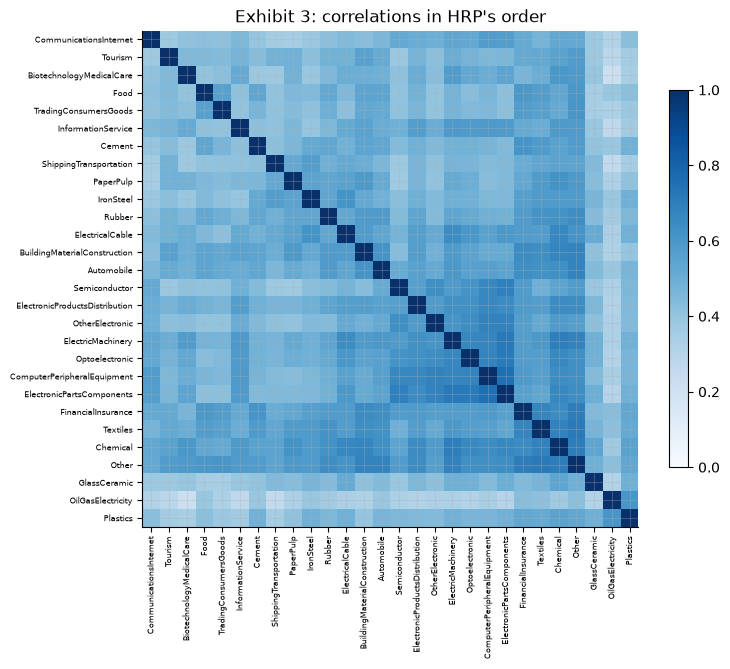

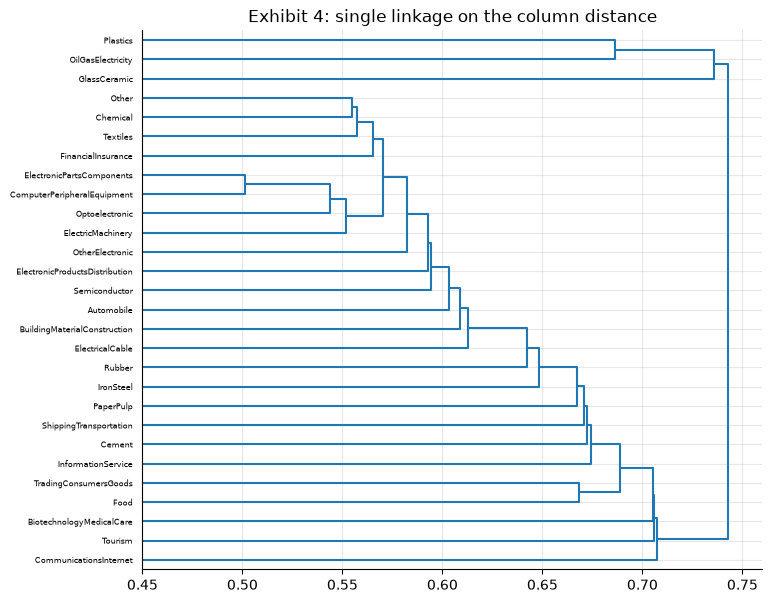

in-sample volatility 1/N (%): 15.75   [book: 15.75]
in-sample volatility IV (%): 15.28   [book: 15.28]
in-sample volatility ERC (%): 15.18   [book: 15.18]
in-sample volatility HRP (%): 14.48   [book: 14.48]
Exhibit 6 (% a year): first half, second half
  1/N                           15.98  15.51
  inverse volatility            15.70  15.20
  ERC                           15.57  15.11
  HRP                           15.22  14.96
  long-only minimum variance    12.74  12.14
  sample minimum variance       11.40  11.78
HRP, second half: 14.96   [book: 14.96]


In [6]:
AGG = ("Electronic", "ChemicalBiotechnologyMedicalCare")
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
FULL_DATA = int(rep["close_1330"].is_not_null().sum()) == rep.height
U28 = sorted(c for c in raw.columns if c not in ("date", "TAIEX", *AGG))
closes = fixed.filter(pl.col("date").is_between(pl.lit("2008-12-01"), pl.lit("2026-10-08"))).sort("date")
ret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in U28]).slice(1)
             .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in U28])))
XU = ret.select(U28).to_numpy()
yrs = (date.fromisoformat("2026-10-08") - date.fromisoformat("2008-12-01")).days / 365.25
AU = XU.shape[0] / yrs
print(f"full data: {FULL_DATA}; U28 T = {XU.shape[0]}, A = {AU:.2f}")
if FULL_DATA:
    show("U28 T", XU.shape[0], ",d", "4,382")

SU = cov0(XU)
dU, DU = distances(XU)
ZU = link(DU)
oU = quasi_diag(ZU, 28)
CU = np.corrcoef(XU, rowvar=False)
off = CU[~np.eye(28, dtype=bool)]
print(f"correlations {off.min():.3f} .. {off.max():.3f}; first merge {U28[int(ZU[0, 0])]} + {U28[int(ZU[0, 1])]} "
      f"at {ZU[0, 2]:.4f}, root {ZU[-1, 2]:.4f}")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(CU[np.ix_(oU, oU)], vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(28), [U28[i] for i in oU], rotation=90, fontsize=6)
ax.set_yticks(range(28), [U28[i] for i in oU], fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.7)
ax.set_title("Exhibit 3: correlations in HRP's order")
plt.show()
fig, ax = plt.subplots(figsize=(8, 7))
dendrogram(ZU, orientation="right", labels=U28, ax=ax, color_threshold=0, leaf_font_size=6)
ax.set_title("Exhibit 4: single linkage on the column distance")
ax.set_xlim(0.45, 0.76)
plt.show()

wu_h = hrp(oU, SU)
vu = np.sqrt(np.diag(SU))
wu_iv = (1 / vu) / (1 / vu).sum()
wu_e, _ = newton(AU * SU, np.full(28, 1 / 28))
for nm, w, p in (("1/N", np.full(28, 1 / 28), "15.75"), ("IV", wu_iv, "15.28"), ("ERC", wu_e, "15.18"),
                 ("HRP", wu_h, "14.48")):
    v = 100 * math.sqrt(AU) * vol(w, SU)
    show(f"in-sample volatility {nm} (%)", v, ".2f", p) if FULL_DATA else print(nm, f"{v:.2f}")

H = XU.shape[0] // 2
S1, S2h = cov0(XU[:H]), cov0(XU[H:])
v1 = np.sqrt(np.diag(S1))
R_ = cholesky(AU * S1, lower=False)
z, _ = nnls(R_, solve_triangular(R_, np.ones(28), trans="T"))
mvs = np.linalg.solve(S1, np.ones(28))
halves = {"1/N": np.full(28, 1 / 28), "inverse volatility": (1 / v1) / (1 / v1).sum(),
          "ERC": newton(AU * S1, np.full(28, 1 / 28))[0], "HRP": hrp(quasi_diag(link(distances(XU[:H])[1]), 28), S1),
          "long-only minimum variance": z / z.sum(), "sample minimum variance": mvs / mvs.sum()}
print("Exhibit 6 (% a year): first half, second half")
for nm, w in halves.items():
    print(f"  {nm:28s} {100 * math.sqrt(AU) * vol(w, S1):6.2f} {100 * math.sqrt(AU) * vol(w, S2h):6.2f}")
if FULL_DATA:
    show("HRP, second half", 100 * math.sqrt(AU) * vol(halves["HRP"], S2h), ".2f", "14.96")

## Part 6 — R6 out of sample and R8 at every signal

Exhibit 5 and Example 7 from the through case's targets; then R8's two volatilities at each signal, its exposure (31.7) checked against the through case, Example 8, the EWMA matrix identity (31.8) and Exhibit 7.

R6 over the 92 signals (%): mean [16.1 18.4 32.8 22.1 10.6] min [13.3 16.2 29.7 18.6  8.5] max [18.3 21.8 37.4 27.5 12.9]
ex-post shares on the 1845 joint rows from 2019-03-05 (%): [20.5 19.2 19.2 23.1 18. ]
Example 8: sigma_bar a day: 0.0034991   [book: 0.0034991]
the EWMA a day: 0.0041204   [book: 0.0041204]
L: 0.8492   [book: 0.8492]
lambda^504 = 2.9e-14; exposure: mean 1.14, at the cap 14, min 0.295 on 2020-04-01
(31.8): w'Sigma w against the portfolio EWMA, largest gap over the signals / sigma_bar^2: 3.1e-15


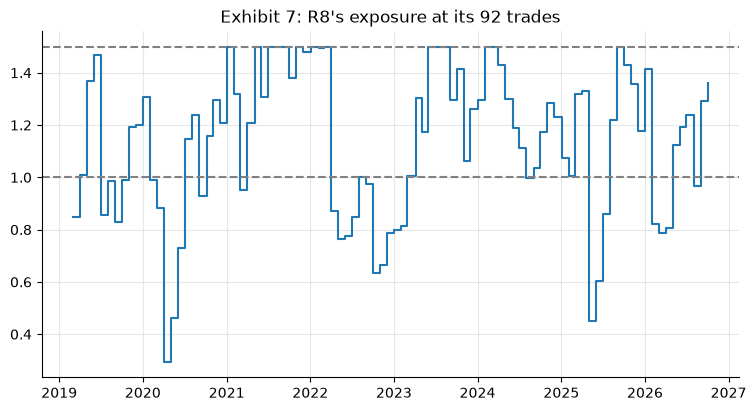

In [7]:
R8, _ = targets("R8")
W6 = np.array([newton(A * cov0(X[r - WINDOW:r]), b5)[0] for _, _, r in sched])
assert np.abs(W6 - R6).max() < 1e-12
print("R6 over the 92 signals (%): mean", np.round(100 * W6.mean(0), 1), "min", np.round(100 * W6.min(0), 1),
      "max", np.round(100 * W6.max(0), 1))
i_oos = next(i for i, d in enumerate(est_dates) if d > sched[0][1])
post = shares(W6.mean(0), A * cov0(X[i_oos:]))
print(f"ex-post shares on the {len(est_dates) - i_oos} joint rows from {est_dates[i_oos]} (%):", np.round(100 * post, 1))


def ewma_path(p, start):
    s2 = start
    for r in p:
        s2 = LAM * s2 + (1 - LAM) * r * r
    return s2


sbar, sfc = [], []
for k, (_, _, r) in enumerate(sched):
    p = X[r - WINDOW:r] @ W6[k]
    sbar.append(math.sqrt(np.mean(p**2)))
    sfc.append(math.sqrt(ewma_path(p, np.mean(p**2))))
sbar, sfc = np.array(sbar), np.array(sfc)
L = np.minimum(CAP, sbar / sfc)
assert np.abs(L[:, None] * W6 - R8).max() < 1e-12
show("Example 8: sigma_bar a day", sbar[0], ".7f", "0.0034991")
show("the EWMA a day", sfc[0], ".7f", "0.0041204")
show("L", L[0], ".4f", "0.8492")
print(f"lambda^504 = {LAM ** 504:.1e}; exposure: mean {L.mean():.2f}, at the cap {int((L >= CAP - EPS).sum())}, "
      f"min {L.min():.3f} on {trades[int(L.argmin())]}")

err = 0.0
for k, (_, _, r) in enumerate(sched):
    xx = X[r - WINDOW:r]
    Sig = xx.T @ xx / WINDOW                  # the window's uncentred second moments, the start
    for row in xx:
        Sig = LAM * Sig + (1 - LAM) * np.outer(row, row)
    err = max(err, abs(W6[k] @ Sig @ W6[k] - sfc[k] ** 2) / sbar[k] ** 2)
print(f"(31.8): w'Sigma w against the portfolio EWMA, largest gap over the signals / sigma_bar^2: {err:.1e}")

fig, ax = plt.subplots()
td = [np.datetime64(t) for t in trades]
ax.step(td, L, where="post")
ax.axhline(1, ls="--", c="grey"); ax.axhline(CAP, ls="--", c="grey")
ax.set_title("Exhibit 7: R8's exposure at its 92 trades"); plt.show()

## Part 7 — Holding months, QLIKE and April 2025

A holding month runs from the session after a trade through the next trade; the partial last one is left out. The realized volatility is the uncentred RMS of the daily net returns of `rule_wealth.csv`, divided by $\bar\sigma_t$ at the signal (both daily). QLIKE is (26.8) with $V$ the holding month's mean squared daily return of R6.

R6: median ratio: 0.83   [book: 0.83]
R6: SD of the log ratio: 0.421   [book: 0.421]
   above 1.5: 11, below 2/3: 21
R8: median ratio: 0.98   [book: 0.98]
R8: SD of the log ratio: 0.421   [book: 0.421]
   above 1.5: 11, below 2/3: 13


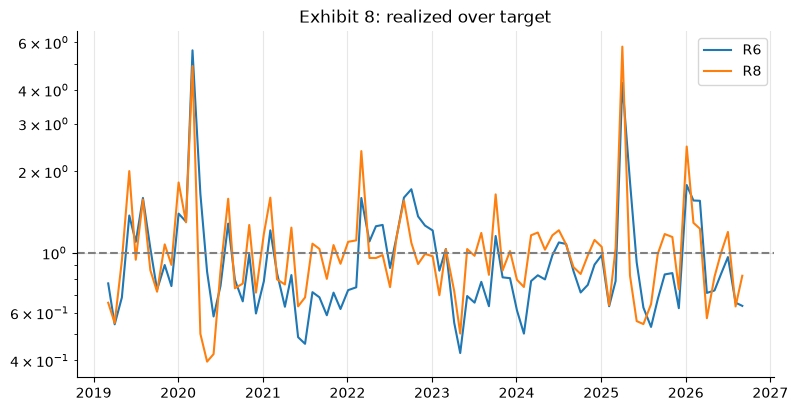

mean QLIKE, window: 0.691   [book: 0.691]
mean QLIKE, EWMA: 0.791   [book: 0.791]
EWMA wins 56 holding months (gain 17.25), loses 35 (cost 26.37); largest loss 13.3 from 2025-04-02
Example 10: the EWMA on 7 April (%): 23.58   [book: 23.58]
its implied exposure: 0.33   [book: 0.33]
R8's ratio from 2 April 2025: 5.78   [book: 5.78]
annualized with A (%): 45.3   [book: 45.3]


In [8]:
rw = pl.read_csv(DATA / "rule_wealth.csv", schema_overrides={"date": pl.Utf8})
ratio, msq = {}, {}
for rule in ("R6", "R8"):
    p = rw.filter(pl.col("rule") == pl.lit(rule)).sort("date")
    dates_p, wealth = p["date"].to_list(), p["wealth"].to_numpy()
    r = wealth[1:] / wealth[:-1] - 1
    ii = [dates_p.index(t) for t in trades]
    msq[rule] = np.array([np.mean(r[ii[m]:ii[m + 1]] ** 2) for m in range(len(ii) - 1)])
    ratio[rule] = np.sqrt(msq[rule]) / sbar[:-1]
starts = [dates_p[ii[m] + 1] for m in range(len(ii) - 1)]
for rule, (pm, ps) in (("R6", ("0.83", "0.421")), ("R8", ("0.98", "0.421"))):
    q = ratio[rule]
    show(f"{rule}: median ratio", np.quantile(q, 0.5, method="inverted_cdf"), ".2f", pm)
    show(f"{rule}: SD of the log ratio", np.log(q).std(), ".3f", ps)
    print(f"   above 1.5: {(q > 1.5 + EPS).sum()}, below 2/3: {(q < 2 / 3 - EPS).sum()}")
fig, ax = plt.subplots()
sd = [np.datetime64(s) for s in starts]
ax.semilogy(sd, ratio["R6"], label="R6"); ax.semilogy(sd, ratio["R8"], label="R8")
ax.axhline(1, ls="--", c="grey"); ax.legend(); ax.set_title("Exhibit 8: realized over target"); plt.show()

V = msq["R6"]
ql = {nm: V / F - np.log(V / F) - 1 for nm, F in (("window", sbar[:-1] ** 2), ("EWMA", sfc[:-1] ** 2))}
gap = ql["EWMA"] - ql["window"]
show("mean QLIKE, window", ql["window"].mean(), ".3f", "0.691")
show("mean QLIKE, EWMA", ql["EWMA"].mean(), ".3f", "0.791")
print(f"EWMA wins {(gap < 0).sum()} holding months (gain {-gap[gap < 0].sum():.2f}), loses {(gap > 0).sum()} "
      f"(cost {gap[gap > 0].sum():.2f}); largest loss {gap.max():.1f} from {starts[int(gap.argmax())]}")

k25 = [t for t in trades].index("2025-04-01")
r25 = sched[k25][2]
p25 = X[r25 - WINDOW:r25] @ W6[k25]
s2 = ewma_path(p25, np.mean(p25**2))
j = r25
while est_dates[j] <= "2025-04-07":
    s2 = LAM * s2 + (1 - LAM) * (X[j] @ W6[k25]) ** 2
    j += 1
show("Example 10: the EWMA on 7 April (%)", 100 * math.sqrt(A * s2), ".2f", "23.58")
show("its implied exposure", min(CAP, sbar[k25] / math.sqrt(s2)), ".2f", "0.33")
show("R8's ratio from 2 April 2025", ratio["R8"][k25], ".2f", "5.78")
show("annualized with A (%)", 100 * math.sqrt(A * msq["R8"][k25]), ".1f", "45.3")

## Part 8 — A risk-triggered R8 (an in-sample illustration)

The rule and its threshold were fixed by the editor on 24 October 2026, before any lab result. R8 keeps its month-end trades. In addition, after each close the EWMA of the book's funds, R6's drifted weights, is updated with the day's return; when the exposure it implies, $\min(1.5,\bar\sigma_t/\sigma)$ with the last signal's $\bar\sigma_t$, differs from the held exposure by more than 0.5, the book trades at the next session's close to that exposure times the last signal's R6 weights, with the through case's costs. (The exposure is the one implied at the triggering close; a month-end trade on the same day takes precedence.) The cell first rebuilds R8's net path with the wealth recursion (27.1)–(27.3) and checks it against `rule_wealth.csv`. Choosing the threshold by its results would be the search of LM34.

In [9]:
i0 = wd.index(trades[0])
by_trade = {t: k for k, t in enumerate(trades)}
by_signal = {s: k for k, (s, _, _) in enumerate(sched)}


def run(trigger=None):
    h, c, path, n_trig = np.zeros(5), 1.0, [], 0
    state, pending = None, None
    for i in range(i0, len(wd)):
        held = h.copy()
        if i > i0:
            h = h * (1 + WR[i])
            c *= 1 + (RF if c >= 0 else RF + SPREAD) / Aw
        W = h.sum() + c
        f = None
        if wd[i] in by_trade:
            f, pending = R8[by_trade[wd[i]]], None
        elif pending is not None and traded[i].all():
            f, pending = pending, None
            n_trig += 1
        if f is not None:
            Wn = W
            for _ in range(100):
                delta = Wn * f - h
                new = W - (COMMISSION * np.abs(delta).sum() + TAX @ np.clip(-delta, 0, None))
                if abs(new - Wn) < 1e-15 * W:
                    break
                Wn = new
            h, c, W = Wn * f, Wn * (1 - f.sum()), Wn
        path.append(W)
        if trigger is None:
            continue
        if wd[i] in by_signal:                # a new signal: restart from its own forecast
            k = by_signal[wd[i]]
            state = [sfc[k] ** 2, sbar[k], W6[k]]
        elif state is not None and held.sum() > 0:
            r_book = held @ WR[i] / held.sum()
            state[0] = LAM * state[0] + (1 - LAM) * r_book**2
        if state is not None and pending is None and W > 0:
            implied = min(CAP, state[1] / math.sqrt(state[0]))
            if abs(implied - h.sum() / W) > trigger:
                pending = implied * state[2]
    return np.array(path), n_trig


base_path, _ = run()
ref = rw.filter(pl.col("rule") == pl.lit("R8")).sort("date")["wealth"].to_numpy()
print(f"R8 rebuilt by the wealth recursion: largest relative gap {np.abs(base_path / ref - 1).max():.1e}")
assert np.abs(base_path / ref - 1).max() < 1e-10
trig_path, n_trig = run(trigger=0.5)
rt = trig_path[1:] / trig_path[:-1] - 1
ii = [wd[i0:].index(t) for t in trades]
q_trig = np.sqrt([np.mean(rt[ii[m]:ii[m + 1]] ** 2) for m in range(len(ii) - 1)]) / sbar[:-1]
print(f"trigger trades: {n_trig}; holding-month ratio, median {np.quantile(q_trig, 0.5, method='inverted_cdf'):.2f} "
      f"(R8 {np.quantile(ratio['R8'], 0.5, method='inverted_cdf'):.2f}), SD of the log ratio {np.log(q_trig).std():.3f} "
      f"(R8 {np.log(ratio['R8']).std():.3f}); April 2025 {q_trig[k25]:.2f} (R8 {ratio['R8'][k25]:.2f})")
print("One threshold, chosen before any result: whether another threshold does better is LM34's search, and LM33's "
      "tests would count every threshold tried.")

R8 rebuilt by the wealth recursion: largest relative gap 0.0e+00
trigger trades: 7; holding-month ratio, median 0.98 (R8 0.98), SD of the log ratio 0.365 (R8 0.421); April 2025 3.77 (R8 5.78)
One threshold, chosen before any result: whether another threshold does better is LM34's search, and LM33's tests would count every threshold tried.


## Part 9 — Practice problems 6 and 8

In [10]:
Cp = np.array([[1.0, 0.8, 0.1], [0.8, 1.0, 0.2], [0.1, 0.2, 1.0]])
vp = np.array([0.20, 0.25, 0.10])
dp = np.sqrt((1 - Cp) / 2)
np.fill_diagonal(dp, 0.0)
Dp = np.sqrt(((dp[:, :, None] - dp[:, None, :]) ** 2).sum(axis=0))
Dp = (Dp + Dp.T) / 2
np.fill_diagonal(Dp, 0.0)
Zp = link(Dp)
op = quasi_diag(Zp, 3)
wpp = hrp(op, np.outer(vp, vp) * Cp)
print("problem 6: d", np.round([dp[0, 1], dp[0, 2], dp[1, 2]], 4), "column distances",
      np.round([Dp[0, 1], Dp[0, 2], Dp[1, 2]], 4), "order", [i + 1 for i in op])
show("problem 6: weight of asset 3", wpp[2], ".4f", "0.8128")
print("weights:", np.round(wpp, 4))
for f_, p in ((0.05, "-4.5072"), (0.16, "-1.4969")):
    Lp = min(1.5, 0.08 / f_)
    book = Lp * -0.03 + (1 - Lp) * (RF if Lp < 1 else RF + SPREAD) / 243.57
    show(f"problem 8: L {Lp:.1f}, book return (%)", 100 * book, ".4f", p)

problem 6: d [0.3162 0.6708 0.6325] column distances [0.4489 1.     0.9622] order [3, 1, 2]
problem 6: weight of asset 3: 0.8128   [book: 0.8128]
weights: [0.1141 0.073  0.8128]
problem 8: L 1.5, book return (%): -4.5072   [book: -4.5072]
problem 8: L 0.5, book return (%): -1.4969   [book: -1.4969]


## Part 10 — Extension: a GARCH-scaled R8

LM26's EWMA forecast for every later day equals tomorrow's. Replace it by a GARCH(1,1) fitted on each window (arch, LM26's settings: constant mean, normal innovations, returns in percent) and average its forecast (26.4) over the next 21 sessions, a horizon fixed before any lab result. Compare its QLIKE against the window's and the EWMA's over the 91 holding months. It is one more variant, not a candidate: LM33's tests would count it.

In [11]:
fg = []
for k, (_, _, r) in enumerate(sched):
    p = 100 * (X[r - WINDOW:r] @ W6[k])
    res = arch_model(p, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
    fg.append(res.forecast(horizon=21, reindex=False).variance.to_numpy()[0].mean() / 1e4)
fg = np.array(fg)
ql_g = V / fg[:-1] - np.log(V / fg[:-1]) - 1
print(f"mean QLIKE: window {ql['window'].mean():.3f}, EWMA {ql['EWMA'].mean():.3f}, GARCH {ql_g.mean():.3f}")
# your code: scale R6 by min(1.5, sigma_bar / sqrt(fg)) and rebuild its holding-month ratios with run()

mean QLIKE: window 0.691, EWMA 0.791, GARCH 0.676
